**Code repository:** [github.com/dabenchen04/math546-project-unemploy-forecast](https://github.com/dabenchen04/math546-project-unemploy-forecast)

# Problem, data, and evaluation design

## Forecasting question

We forecast the U.S. unemployment rate (`UNRATE`, percent) one, two, and three months ahead. We take the view of a labor-market analyst who updates a near-term outlook each month, right after the Bureau of Labor Statistics publishes unemployment for reference month $t$. We predict $u_{t+1}$, $u_{t+2}$, and $u_{t+3}$ at that origin and measure errors in percentage points. We ask whether macroeconomic information improves on **persistence**, the forecast that carries the latest published rate forward.

## Data and information available at each origin

We use the instructor's frozen January 2026 vintage of [FRED-MD](https://www.stlouisfed.org/research/economists/mccracken/fred-databases), loaded with the course loader, which verifies the snapshot checksum. We pair unemployment with four predictors that summarize labor-market inflows, monetary policy, prices, and output. We list in @tbl-variables the value of each series that we treat as published when the month-$t$ forecast is issued. We lag CPI inflation and industrial production by one month because their month-$t$ values are released after the unemployment report.

| Series | Definition | Value used at origin $t$ | Release-timing reason |
|---|---|---|---|
| `UNRATE` | Unemployment rate (%) | $u_t$ | Its release defines the origin. |
| `FEDFUNDS` | Effective federal funds rate (%) | $r_t$ | Daily rates are published the next business day. |
| `CLAIMSx` | Initial claims, monthly average of weekly counts | $\mathrm{Claims}_t$ | Weekly counts are released within days. |
| `CPIAUCSL` | Monthly inflation, $\pi_t=100\,\Delta\log \mathrm{CPI}_t$ | $\pi_{t-1}$ | Month-$t$ CPI is released in mid-month $t+1$. |
| `INDPRO` | Industrial production index | $\mathrm{IP}_{t-1}$ | Month-$t$ output is released in mid-month $t+1$. |

: Series and the information assumed available at origin $t$. {#tbl-variables}

We keep 1960 observations only to construct lags, and every model starts estimation in 1961. We work with revised data, so our backtest measures retrospective accuracy under these release assumptions and cannot reproduce the values forecasters saw in real time. We reproduce every result by running this notebook from top to bottom in the course Python 3.12 environment from the `Capstone` folder, which also writes the final-test forecasts and scores to `results/final_test/`.

In [1]:
#| label: setup
from pathlib import Path
import sys, json, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss, acf, coint
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.util import comp_matrix
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_coint_rank
import sklearn
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from joblib import parallel_backend

pd.set_option("display.max_columns", None)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# The notebook runs from the Capstone folder or its parent course folder.
project = next((p for p in (Path.cwd(), Path.cwd() / "Capstone")
                if (p / "capstone_support" / "capstone_data.py").is_file()), None)
if project is None:
    raise FileNotFoundError("Open this notebook from Capstone or its parent course folder.")
sys.path.insert(0, str(project / "capstone_support"))
from capstone_data import load_dataset, chronological_split

raw_panel = load_dataset("fred_md")
train, validation, test = chronological_split(raw_panel)
ANALYSIS_START = "1961-01-01"
train = train.loc[ANALYSIS_START:].copy()

# Monthly series used throughout: unemployment, the four predictors, and monthly inflation.
series = raw_panel.loc[ANALYSIS_START:, ["UNRATE", "FEDFUNDS", "CLAIMSx", "INDPRO"]].copy()
series["CPI_inflation_mlog"] = 100 * np.log(raw_panel["CPIAUCSL"]).diff()
COLUMNS = ["UNRATE", "FEDFUNDS", "CPI_inflation_mlog", "CLAIMSx", "INDPRO"]
series = series[COLUMNS]
descriptive = series.loc[train.index]
assert series.notna().all().all() and len(descriptive) == 456

# Origins: every three-month target window lies inside its evaluation block.
VALIDATION_ORIGINS = pd.date_range("1998-12-01", "2011-09-01", freq="MS")
TEST_ORIGINS = pd.date_range("2011-12-01", "2024-09-01", freq="MS")
HORIZONS = (1, 2, 3)
MODEL_COLORS = {"Persistence": "#6E6E6E", "ARIMA(4,1,1)": "#174A7E",
                "VECM(9), rank 2": "#B35826", "Random forest": "#397761"}


def persistence_forecasts(levels, origins):
    """Carry the latest observed unemployment rate forward to all three horizons."""
    return pd.DataFrame([{"Model": "Persistence", "Origin": o, "Horizon": h,
                          "Target month": o + pd.offsets.MonthBegin(h),
                          "Forecast": float(levels.loc[:o].iloc[-1])}
                         for o in origins for h in HORIZONS])


def attach_actuals(forecasts, actual, origins):
    """Join outcomes only after all forecasts exist; verify identical scoring pairs."""
    expected = pd.MultiIndex.from_product([origins, HORIZONS], names=["Origin", "Horizon"])
    for _, group in forecasts.groupby("Model"):
        assert pd.MultiIndex.from_frame(group[["Origin", "Horizon"]]).equals(expected)
    scored = forecasts.copy()
    scored["Actual"] = scored["Target month"].map(actual)
    assert scored["Actual"].notna().all()
    scored["Error"] = scored["Forecast"] - scored["Actual"]
    return scored


def accuracy_table(scored, order):
    """Standard accuracy summary used for every validation and test comparison."""
    sq = scored.assign(SE=scored["Error"] ** 2, AE=scored["Error"].abs())
    by_h = np.sqrt(sq.groupby(["Model", "Horizon"])["SE"].mean()).unstack("Horizon")
    by_h.columns = [f"RMSE h={h}" for h in by_h.columns]
    pooled = sq.groupby("Model").agg(Pairs=("SE", "size"), MSE=("SE", "mean"), MAE=("AE", "mean"))
    table = by_h.join(pooled)
    table.insert(3, "Pooled RMSE", np.sqrt(table.pop("MSE")))
    table = table.rename(columns={"MAE": "Pooled MAE"})
    table["RMSE / persistence"] = table["Pooled RMSE"] / table.at["Persistence", "Pooled RMSE"]
    table["MAE / persistence"] = table["Pooled MAE"] / table.at["Persistence", "Pooled MAE"]
    table = table.loc[order, ["Pairs", "RMSE h=1", "RMSE h=2", "RMSE h=3", "Pooled RMSE",
                              "Pooled MAE", "RMSE / persistence", "MAE / persistence"]]
    table.index.name = "Model"
    return table


def fmt(table, digits=3):
    """Round numeric columns for display without changing stored values."""
    return table.round(digits)

In [2]:
#| label: tbl-splits
#| tbl-cap: "Chronological evaluation blocks. Each origin forecasts three target months inside its block, so every model is scored on the same 462 origin–horizon pairs per block."
split_table = pd.DataFrame({
    "Months": [len(train), len(validation), len(test)],
    "Forecast origins": ["—", "Dec 1998–Sep 2011 (154)", "Dec 2011–Sep 2024 (154)"],
    "Scored pairs per model": ["—", 154 * 3, 154 * 3],
    "Role": ["Identify and narrow candidates", "Choose one model per family", "Compare frozen families once"],
}, index=pd.Index(["Training, 1961–1998", "Validation, 1999–2011", "Test, 2012–2024"], name="Block"))
display(split_table)

,Months,Forecast origins,Scored pairs per model,Role
Block,,,,
"Training, 1961–1998",456,—,—,Identify and narrow candidates
"Validation, 1999–2011",156,Dec 1998–Sep 2011 (154),462,Choose one model per family
"Test, 2012–2024",156,Dec 2011–Sep 2024 (154),462,Compare frozen families once


We show the full history in @fig-unrate to place the three blocks in context. The validation block contains the 2001 and 2008–09 recessions, and the test block contains the April 2020 jump to 14.8%, which dominates the test errors in @sec-test.

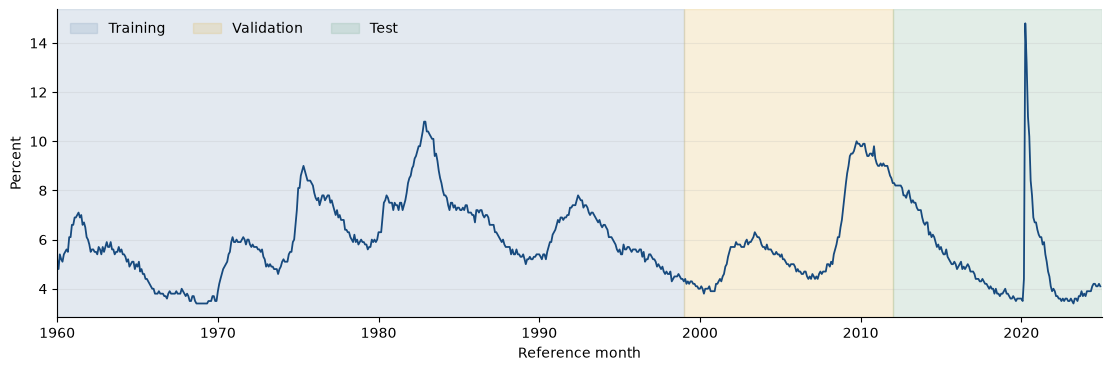

In [3]:
#| label: fig-unrate
#| fig-cap: "U.S. unemployment rate, 1960–2024, with the training, validation, and test blocks."
full_u = raw_panel.loc["1960-01-01":"2024-12-01", "UNRATE"]
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
for start, end, color, label in [("1960-01-01", "1999-01-01", "#7394B5", "Training"),
                                 ("1999-01-01", "2012-01-01", "#E0B34A", "Validation"),
                                 ("2012-01-01", "2025-01-01", "#6EA88B", "Test")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=.2, label=label)
ax.plot(full_u.index, full_u, color="#174A7E", linewidth=1.3)
ax.set(xlabel="Reference month", ylabel="Percent", xlim=(full_u.index[0], pd.Timestamp("2025-01-01")))
ax.legend(loc="upper left", frameon=False, ncols=3)
ax.grid(axis="y", alpha=.2)
plt.show()

We plot the predictors over the training period in @fig-predictors. We see initial claims surge in every training recession, which is why we expect claims to carry early information about unemployment. Because industrial production trends upward, we test it for stationarity around a trend in @sec-var.

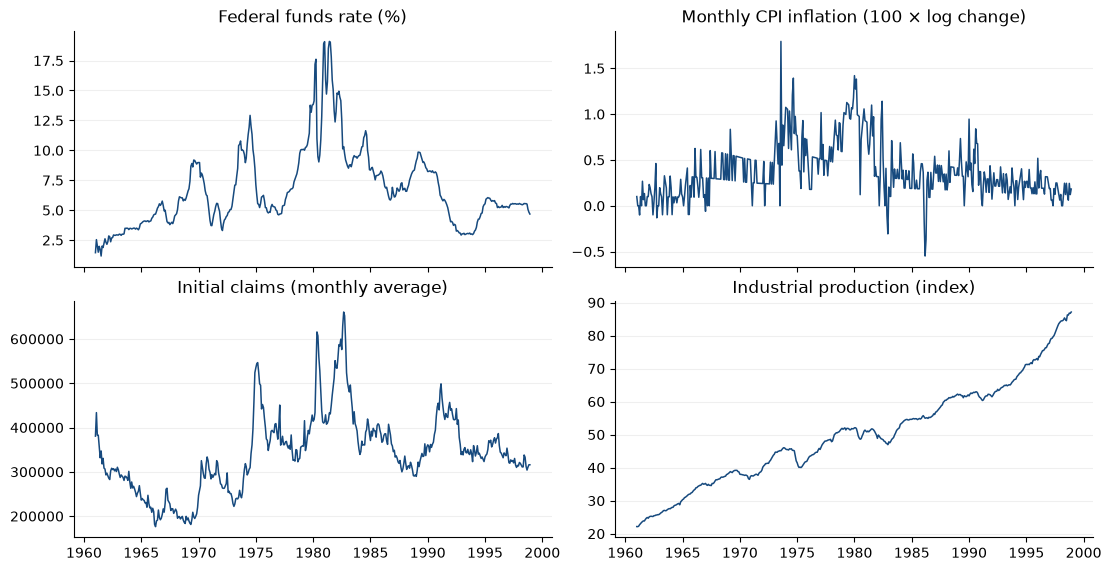

In [4]:
#| label: fig-predictors
#| fig-cap: "Predictors over the training period, 1961–1998."
labels = {"UNRATE": "Unemployment rate (%)", "FEDFUNDS": "Federal funds rate (%)",
          "CPI_inflation_mlog": "Monthly CPI inflation (100 × log change)",
          "CLAIMSx": "Initial claims (monthly average)", "INDPRO": "Industrial production (index)"}
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True, layout="constrained")
for ax, name in zip(axes.flat, COLUMNS[1:]):
    ax.plot(descriptive.index, descriptive[name], color="#174A7E", linewidth=1.1)
    ax.set(title=labels[name])
    ax.grid(axis="y", alpha=.2)
axes[1, 0].ticklabel_format(axis="y", style="plain")
plt.show()

## Evaluation rules

We apply the same rules to every model.

1. **Expanding-window origins.** At each origin we refit the model using only data dated at or before $t$. We drop origins whose three-month window would cross a block boundary, which leaves 154 origins and 462 scored pairs per model in each block (@tbl-splits).
2. **Three selection stages.** We use training data to identify and narrow candidates, validation to choose one representative per family, and the test block once to compare the frozen representatives. We freeze specifications and refit coefficients at every origin.
3. **Metrics.** We define the error as forecast minus actual. Pooled RMSE over the 462 pairs is our primary metric; we also report RMSE by horizon, pooled MAE, and both ratios to persistence, where values below one beat the benchmark. In the test we add Diebold–Mariano tests and 90% interval coverage.
4. **Leakage controls.** We generate and store every forecast before joining outcomes, assert that no training target postdates its origin, and, for each family, perturb all data after the first origin to confirm that its forecasts do not change.

## Candidate models

| Family | Candidates | How we select | Section |
|---|---|---|---|
| Benchmark | Persistence, $\hat u_{t+h\mid t}=u_t$ | No estimation | All |
| Univariate ARIMA | ARIMA(3,1,0), (4,1,0), (5,1,0), (4,1,1) | Stationarity tests, ACF/PACF, AIC/BIC, Ljung–Box; validation RMSE | @sec-arima |
| Multivariate system | VAR(2), VAR(9), rank-2 VECM with nine levels lags | Information criteria, cointegration tests; validation RMSE | @sec-var |
| Tree ensembles | Random forest, gradient boosting | Time-series cross-validation on training; validation RMSE | @sec-trees |

: Model families and selection procedure. {#tbl-candidates}

# Univariate ARIMA {#sec-arima}

We start with a model that uses only the unemployment history. We use it to measure how much of the near-term path momentum alone can predict.

## Order of integration

In [5]:
#| label: stationarity-helper
def kpss_pvalue(values, regression):
    """KPSS p-values are tabulated only between 0.01 and 0.10; report bounds outside."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InterpolationWarning)
        stat, p, lags, crit = kpss(values, regression=regression, nlags="auto", result_object=False)
    bounded = any(issubclass(w.category, InterpolationWarning) for w in caught)
    text = ("< 0.01" if p <= 0.01 else "> 0.10") if bounded else f"{p:.3f}"
    return stat, text, stat > crit["5%"]


def stationarity_rows(names, data, trend_series=("INDPRO",)):
    """ADF (null: unit root) and KPSS (null: stationarity) in levels and first differences."""
    rows = []
    for name in names:
        for transform, values in [("Level", data[name]), ("First difference", data[name].diff().dropna())]:
            det = "ct" if (name in trend_series and transform == "Level") else "c"
            adf = adfuller(values, maxlag=12, regression=det, autolag="AIC", result_object=False)
            k_stat, k_p, k_rej = kpss_pvalue(values, det)
            rows.append({"Series": name, "Transform": transform,
                         "Deterministic": "Constant + trend" if det == "ct" else "Constant",
                         "ADF p-value": "< 0.001" if adf[1] < .001 else f"{adf[1]:.3f}",
                         "ADF rejects unit root": adf[1] < .05,
                         "KPSS p-value": k_p, "KPSS rejects stationarity": bool(k_rej)})
    return pd.DataFrame(rows).set_index(["Series", "Transform"])

In [6]:
#| label: tbl-unrate-stationarity
#| tbl-cap: "ADF and KPSS tests for unemployment, training sample 1961–1998 (5% decisions; ADF lags chosen by AIC up to 12)."
display(fmt(stationarity_rows(["UNRATE"], descriptive), 4))

Deterministic ADF p-value  ADF rejects unit root  \
Series Transform                                                           
UNRATE Level                 Constant       0.104                  False   
       First difference      Constant     < 0.001                   True   

                        KPSS p-value  KPSS rejects stationarity  
Series Transform                                                 
UNRATE Level                   0.014                       True  
       First difference       > 0.10                      False

We use ADF and KPSS together because their null hypotheses are opposite. In levels, ADF does not reject a unit root while KPSS rejects stationarity; after one difference, ADF rejects and KPSS does not. We see the same evidence in the autocorrelations of @fig-du: the level ACF decays slowly and the level PACF is dominated by a first-lag spike of 0.99, while the ACF of the monthly change stays small beyond the first few months. We therefore model monthly changes in unemployment ($d=1$).

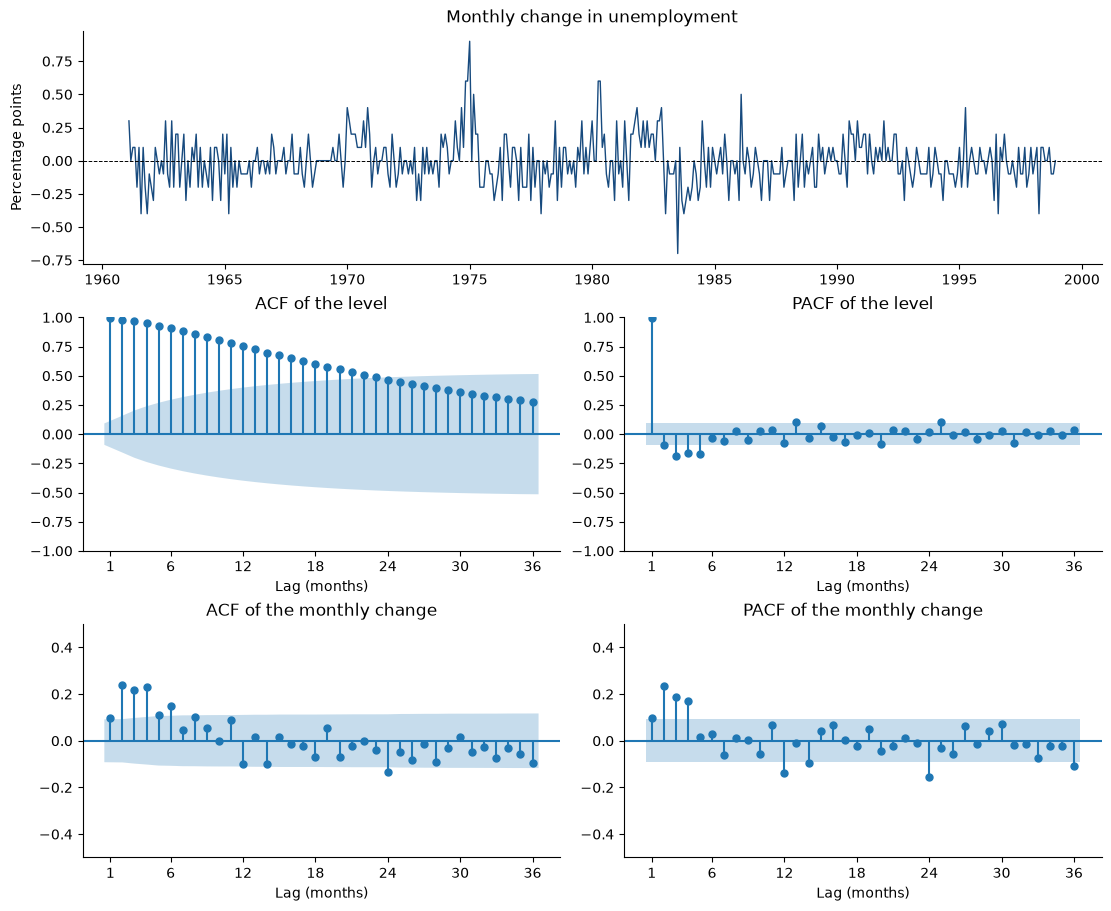

In [7]:
#| label: fig-du
#| fig-cap: "Unemployment over the training period: the monthly change (top), and the ACF and PACF of the level (middle) and of the monthly change (bottom). Bands are approximate 95% limits."
u_level = descriptive["UNRATE"]
du = u_level.diff().dropna()
fig = plt.figure(figsize=(11, 9), layout="constrained")
grid = fig.add_gridspec(3, 2)
ax_top = fig.add_subplot(grid[0, :])
ax_top.plot(du.index, du, color="#174A7E", linewidth=1)
ax_top.axhline(0, color="black", linewidth=.7, linestyle="--")
ax_top.set(ylabel="Percentage points", title="Monthly change in unemployment")
for row, (values, label, ylim) in enumerate([(u_level, "level", (-1, 1)), (du, "monthly change", (-.5, .5))], 1):
    for col, func in enumerate([plot_acf, plot_pacf]):
        ax = fig.add_subplot(grid[row, col])
        kwargs = {"method": "ywm"} if func is plot_pacf else {}
        func(values, lags=36, zero=False, alpha=.05, ax=ax, **kwargs)
        ax.set(title=f"{'ACF' if col == 0 else 'PACF'} of the {label}", xlabel="Lag (months)",
               ylim=ylim, xticks=[1, 6, 12, 18, 24, 30, 36])
plt.show()

## Identifying the order

We omit a drift term because the monthly change fluctuates around zero. We read AR(4) dynamics from its PACF, which has clear spikes through lag 4 and small values afterward. We therefore compare ARIMA(3,1,0), ARIMA(4,1,0), ARIMA(5,1,0), and ARIMA(4,1,1).

## Training fit

In [8]:
#| label: tbl-arima-train
#| tbl-cap: "Training fit of the ARIMA candidates (no drift; Gaussian maximum likelihood on 1961–1998). Ljung–Box tests use standardized one-step innovations with p + q degrees of freedom removed."
ARIMA_ORDERS = [(3, 1, 0), (4, 1, 0), (5, 1, 0), (4, 1, 1)]
u_train = descriptive["UNRATE"].asfreq("MS")
rows = []
for order in ARIMA_ORDERS:
    fit = ARIMA(u_train, order=order, trend="n").fit(method="statespace", method_kwargs={"maxiter": 1500})
    assert fit.mle_retvals["converged"]
    burn = max(int(fit.loglikelihood_burn), int(fit.filter_results.nobs_diffuse))
    innovations = fit.filter_results.standardized_forecasts_error[0, burn:]
    lb = acorr_ljungbox(innovations, lags=[6, 12, 24], model_df=order[0] + order[2], return_df=True)
    rows.append({"Model": f"ARIMA{order}".replace(" ", ""), "AIC": fit.aic, "BIC": fit.bic,
                 **{f"Ljung–Box p, lag {m}": lb.at[m, "lb_pvalue"] for m in (6, 12, 24)}})
arima_train = pd.DataFrame(rows).set_index("Model")
display(fmt(arima_train, 3))

,AIC,BIC,"Ljung–Box p, lag 6","Ljung–Box p, lag 12","Ljung–Box p, lag 24"
Model,,,,,
"ARIMA(3,1,0)",-299.150,-282.669,0.002,0.002,0.001
"ARIMA(4,1,0)",-310.726,-290.124,0.647,0.069,0.031
"ARIMA(5,1,0)",-308.819,-284.097,0.407,0.050,0.022
"ARIMA(4,1,1)",-308.848,-284.126,0.428,0.052,0.022


We find that ARIMA(4,1,0) has the lowest AIC and BIC and that a fourth AR lag removes the short-lag autocorrelation ARIMA(3,1,0) leaves behind: the lag-6 Ljung–Box p-value rises from 0.002 to 0.647. We still reject at lag 24 for every candidate, so some longer-range dependence remains. We treat Ljung–Box as a screen and let forecast performance choose among the candidates.

## Rolling validation {#sec-arima-validation}

We forecast the monthly change recursively at each origin and add the predicted changes to the latest observed level: $\hat u_{t+h\mid t}=u_t+\sum_{j=1}^{h}\widehat{\Delta u}_{t+j\mid t}$. We retry a non-converged fit once on the same history with BFGS and stop the run if it fails again.

In [9]:
#| label: arima-validation
def arima_forecast(history, order):
    """Fit on history through the origin only and return three-step level forecasts."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        fit = ARIMA(history, order=order, trend="n").fit(method="statespace", method_kwargs={"maxiter": 1500})
        retried = not fit.mle_retvals["converged"] or not np.isfinite(fit.params).all()
        if retried:
            fit = ARIMA(history, order=order, trend="n").fit(
                method="statespace", method_kwargs={"method": "bfgs", "maxiter": 1500, "gtol": 1e-6})
    if not fit.mle_retvals["converged"] or not np.isfinite(fit.params).all():
        raise RuntimeError(f"ARIMA{order} failed at {history.index[-1]:%Y-%m}")
    return fit, retried


u_history = pd.concat([train["UNRATE"], validation["UNRATE"]]).asfreq("MS")
rows, arima_retries = [], 0
for origin in VALIDATION_ORIGINS:
    history = u_history.loc[:origin]
    for order in ARIMA_ORDERS:
        fit, retried = arima_forecast(history, order)
        arima_retries += retried
        for h, value in enumerate(fit.forecast(steps=3), 1):
            rows.append({"Model": f"ARIMA{order}".replace(" ", ""), "Origin": origin, "Horizon": h,
                         "Target month": origin + pd.offsets.MonthBegin(h), "Forecast": float(value)})

# Leakage check: altering every value after the first origin cannot change its forecasts.
perturbed = u_history.copy()
perturbed[perturbed.index > VALIDATION_ORIGINS[0]] += 5.0
first = pd.DataFrame(rows).query("Origin == @VALIDATION_ORIGINS[0]")
for order in ARIMA_ORDERS:
    check, _ = arima_forecast(perturbed.loc[:VALIDATION_ORIGINS[0]], order)
    name = f"ARIMA{order}".replace(" ", "")
    np.testing.assert_allclose(check.forecast(steps=3).to_numpy(),
                               first.query("Model == @name")["Forecast"].to_numpy())

persistence_validation = persistence_forecasts(u_history, VALIDATION_ORIGINS)
arima_validation = attach_actuals(pd.concat([pd.DataFrame(rows), persistence_validation]),
                                  validation["UNRATE"], VALIDATION_ORIGINS)

In [10]:
#| label: tbl-arima-validation
#| tbl-cap: "Rolling validation of the ARIMA candidates, January 1999–December 2011 targets (percentage points)."
arima_table = accuracy_table(arima_validation, ["Persistence"] + [f"ARIMA{o}".replace(" ", "") for o in ARIMA_ORDERS])
display(fmt(arima_table))

,Pairs,RMSE h=1,RMSE h=2,RMSE h=3,Pooled RMSE,Pooled MAE,RMSE / persistence,MAE / persistence
Model,,,,,,,,
Persistence,462,0.166,0.268,0.374,0.282,0.182,1.000,1.000
"ARIMA(3,1,0)",462,0.147,0.222,0.306,0.234,0.169,0.829,0.926
"ARIMA(4,1,0)",462,0.148,0.219,0.298,0.230,0.168,0.815,0.920
"ARIMA(5,1,0)",462,0.147,0.218,0.296,0.229,0.167,0.810,0.915
"ARIMA(4,1,1)",462,0.147,0.218,0.296,0.228,0.167,0.809,0.915


We find that every ARIMA candidate beats persistence at all three horizons. ARIMA(4,1,1) has the lowest pooled RMSE, 0.228 against 0.282 for persistence, but its margin over ARIMA(5,1,0) is only 0.15%, so the AR(4)-type models are practically tied. We freeze **ARIMA(4,1,1) without drift** under our pooled-RMSE rule. We added this candidate after viewing the scores of the first three, so its validation margin is slightly optimistic.

## What the univariate model misses

We see two limits in this model. It extrapolates recent momentum in unemployment and sees nothing outside that series, so it can react to a turning point only after unemployment has already moved; and its residuals keep dependence at long lags. Because layoffs show up in initial claims within weeks, we next let claims and the other predictors inform the forecast.

# Multivariate VAR and VECM {#sec-var}

We model unemployment jointly with the four predictors so that each forecast can use their recent movements. A VAR forecasts all five series together, which supplies the future predictor values a single-equation regression would need. We order the release-aligned vector as
$$z_t=(u_t,\ r_t,\ \pi_{t-1},\ \mathrm{Claims}_t,\ \mathrm{IP}_{t-1})^\top .$$
A levels VAR($K$) is $z_t=c+\sum_{j=1}^{K}A_j z_{t-j}+\varepsilon_t$. If $r$ combinations of the levels are stationary, the same system can be written as a vector error-correction model (VECM),
$$\Delta z_t=c+\alpha\beta^\top z_{t-1}+\sum_{j=1}^{K-1}\Gamma_j\Delta z_{t-j}+\varepsilon_t ,$$
where $\beta^\top z_{t-1}$ measures deviations from $r$ long-run relationships and $\alpha$ sets how fast each variable responds to them.

## A first look: the levels regression

We first regress unemployment on the aligned predictors in levels over 1961–1998 to see whether they move with unemployment at all. We report heteroskedasticity- and autocorrelation-consistent (HAC) standard errors with 12 lags because the residuals are persistent.

In [11]:
#| label: tbl-ols
#| tbl-cap: "Levels regression of unemployment on the aligned predictors, February 1961–December 1998, with 12-lag Bartlett HAC standard errors."
regression_panel = series[["UNRATE", "FEDFUNDS", "CLAIMSx"]].copy()
regression_panel["CPI_inflation_mlog_lag1"] = series["CPI_inflation_mlog"].shift(1)
regression_panel["INDPRO_lag1"] = series["INDPRO"].shift(1)
VAR_COLUMNS = ["UNRATE", "FEDFUNDS", "CPI_inflation_mlog_lag1", "CLAIMSx", "INDPRO_lag1"]
var_levels = regression_panel.loc[train.index, VAR_COLUMNS].dropna().asfreq("MS")
assert var_levels.index[0] == pd.Timestamp("1961-02-01") and len(var_levels) == 455
ols = sm.OLS(var_levels["UNRATE"], sm.add_constant(var_levels[VAR_COLUMNS[1:]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 12, "kernel": "bartlett", "use_correction": True})
ols_table = pd.DataFrame({"Coefficient": ols.params, "HAC SE": ols.bse, "HAC p-value": ols.pvalues})
display(ols_table.style.format("{:.3g}"))

,Coefficient,HAC SE,HAC p-value
const,1.77,0.375,2.43e-06
FEDFUNDS,-0.0187,0.0366,0.61
CPI_inflation_mlog_lag1,-0.426,0.326,0.191
CLAIMSx,1.6e-05,1.21e-06,6.15e-40
INDPRO_lag1,-0.0179,0.00562,0.0015


We find that the regression explains most of the training variation in unemployment ($R^2 = 0.78$). Claims carry the strongest association: higher claims go with higher unemployment (HAC p < 0.001), and industrial production enters negatively (p = 0.002), while the funds rate and inflation add little on their own. @fig-ols shows that the fitted values track the unemployment cycle closely.

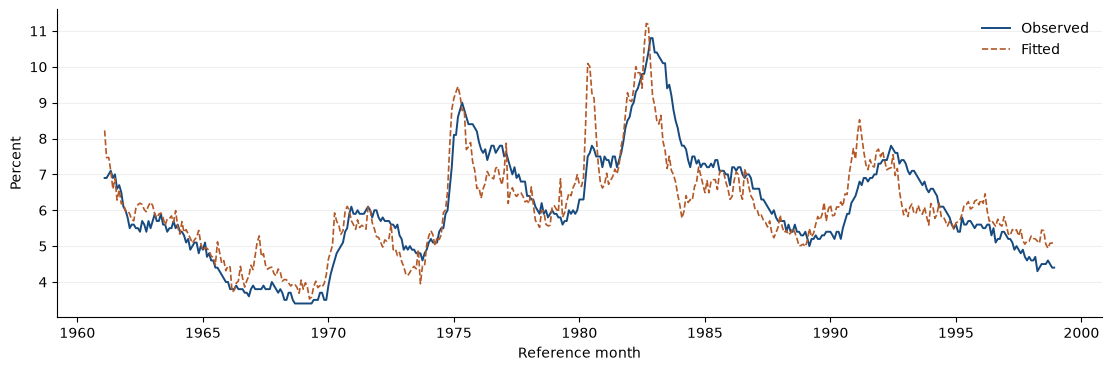

In [12]:
#| label: fig-ols
#| fig-cap: "Observed unemployment and the fitted values of the levels regression, February 1961–December 1998."
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(var_levels.index, var_levels["UNRATE"], color="#174A7E", linewidth=1.4, label="Observed")
ax.plot(var_levels.index, ols.fittedvalues, color="#B35826", linewidth=1.2, linestyle="--", label="Fitted")
ax.set(xlabel="Reference month", ylabel="Percent")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
plt.show()

We take this close fit as motivation for modeling the five series jointly. We also treat it with caution, because a regression among persistent series can fit well even without a stable relationship; we therefore check whether the predictors are integrated and whether the levels are cointegrated.

## Integration of the predictors

In [13]:
#| label: tbl-predictor-stationarity
#| tbl-cap: "ADF and KPSS tests for the four predictors, training sample 1961–1998 (5% decisions). Industrial production levels include a linear trend."
display(fmt(stationarity_rows(COLUMNS[1:], descriptive), 4))

Deterministic ADF p-value  \
Series             Transform                                        
FEDFUNDS           Level                     Constant       0.154   
                   First difference          Constant     < 0.001   
CPI_inflation_mlog Level                     Constant       0.208   
                   First difference          Constant     < 0.001   
CLAIMSx            Level                     Constant       0.073   
                   First difference          Constant     < 0.001   
INDPRO             Level             Constant + trend       0.765   
                   First difference          Constant     < 0.001   

                                     ADF rejects unit root KPSS p-value  \
Series             Transform                                              
FEDFUNDS           Level                             False        0.019   
                   First difference                   True       > 0.10   
CPI_inflation_mlog Level                             False        0.024   
                   First difference                   True       > 0.10   
CLAIMSx            Level                             False       < 0.01   
                   First difference                   True       > 0.10   
INDPRO             Level                             False       < 0.01   
                   First difference                   True       > 0.10   

                                     KPSS rejects stationarity  
Series             Transform                                    
FEDFUNDS           Level                                  True  
                   First difference                      False  
CPI_inflation_mlog Level                                  True  
                   First difference                      False  
CLAIMSx            Level                                  True  
                   First difference                      False  
INDPRO             Level                                  True  
                   First difference                      False

We find that all four predictors follow the same pattern as unemployment: in levels ADF does not reject a unit root and KPSS rejects stationarity, and both decisions reverse after one difference. We see the matching autocorrelation pattern in @fig-predictor-acf: slow ACF decay in levels, with a first PACF lag of 0.98–0.99 for the funds rate, claims, and industrial production and 0.68 for monthly inflation, and quickly fading correlations after differencing. We therefore treat all five series as integrated of order one, which makes the levels regression above spurious unless the series are cointegrated. We test for cointegration after choosing the lag order.

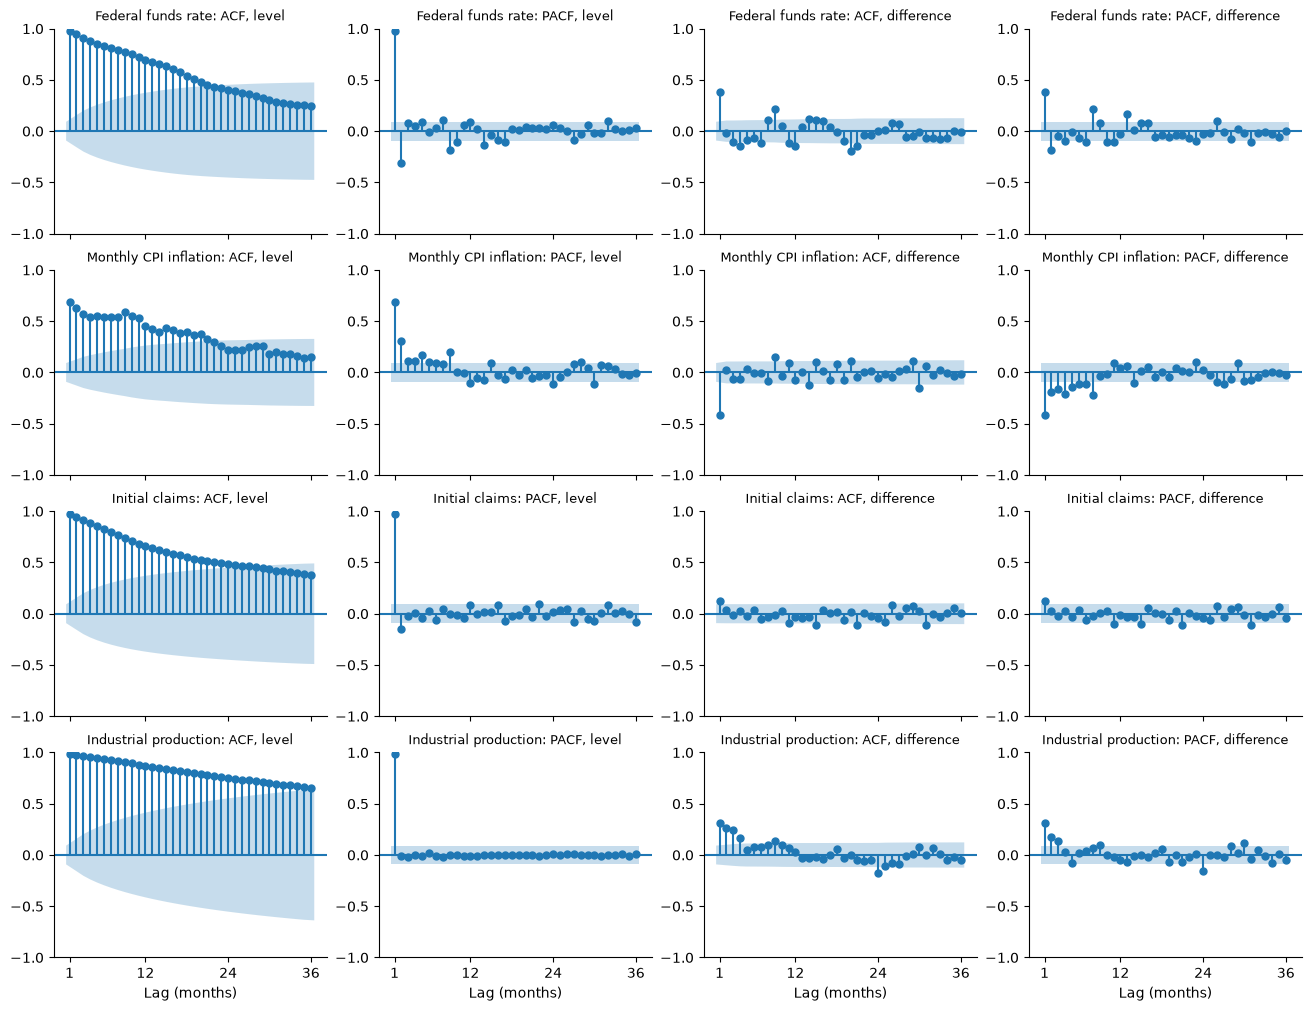

In [14]:
#| label: fig-predictor-acf
#| fig-cap: "ACF and PACF of each predictor in levels (left two columns) and in first differences (right two columns), training sample. Bands are approximate 95% limits."
fig, axes = plt.subplots(4, 4, figsize=(13, 10), sharex=True, layout="constrained")
for row, name in enumerate(COLUMNS[1:]):
    for col, (values, func, title) in enumerate([
            (descriptive[name], plot_acf, "ACF, level"), (descriptive[name], plot_pacf, "PACF, level"),
            (descriptive[name].diff().dropna(), plot_acf, "ACF, difference"),
            (descriptive[name].diff().dropna(), plot_pacf, "PACF, difference")]):
        ax = axes[row, col]
        kwargs = {"method": "ywm"} if func is plot_pacf else {}
        func(values, lags=36, zero=False, alpha=.05, ax=ax, **kwargs)
        ax.set(title=f"{labels[name].split(' (')[0]}: {title}", ylim=(-1, 1))
        ax.title.set_fontsize(9)
for ax in axes[-1]:
    ax.set(xlabel="Lag (months)", xticks=[1, 12, 24, 36])
plt.show()

## Lag order and residual diagnostics

In [15]:
#| label: var-fit
lag_selection = VAR(var_levels).select_order(maxlags=12, trend="c")  # common sample for all K
var_fits = {K: VAR(var_levels).fit(K, trend="c") for K in (2, 9)}
rows = []
for K, fit in var_fits.items():
    modulus = np.abs(np.linalg.eigvals(comp_matrix(fit.coefs)))
    rows.append({"Lag order K": K,
                 "Selected by": ", ".join(c.upper() for c in ("aic", "bic", "hqic")
                                          if lag_selection.selected_orders[c] == K),
                 "Mean coefficients": 5 * (1 + 5 * K),
                 "Largest companion eigenvalue modulus": modulus.max(),
                 **{f"Portmanteau p, lag {H}": fit.test_whiteness(nlags=H, adjusted=True).pvalue
                    for H in (12, 24)}})
var_table = pd.DataFrame(rows).set_index("Lag order K")

In [16]:
#| label: tbl-var
#| tbl-cap: "Levels VAR candidates selected by information criteria (lags 0–12 compared on a common sample). The portmanteau test jointly checks residual autocorrelation in all five equations."
display(var_table.style.format({"Largest companion eigenvalue modulus": "{:.4f}",
                                "Portmanteau p, lag 12": "{:.1e}", "Portmanteau p, lag 24": "{:.1e}"}))

,Selected by,Mean coefficients,Largest companion eigenvalue modulus,"Portmanteau p, lag 12","Portmanteau p, lag 24"
Lag order K,,,,,
2,"BIC, HQIC",55,1.0029,3.9e-16,1.4e-19
9,AIC,230,1.0035,4.6e-07,1.7e-07


We obtain two lags from BIC and HQ and nine from AIC. We find one companion eigenvalue slightly above one in each fitted VAR, which is how a freely estimated unit root appears in a levels VAR. Both fits reject the portmanteau test, so neither captures all of the residual dependence. We see in @fig-var-resid that nine lags shrink the residual autocorrelation in every equation, most visibly for the funds rate and inflation.

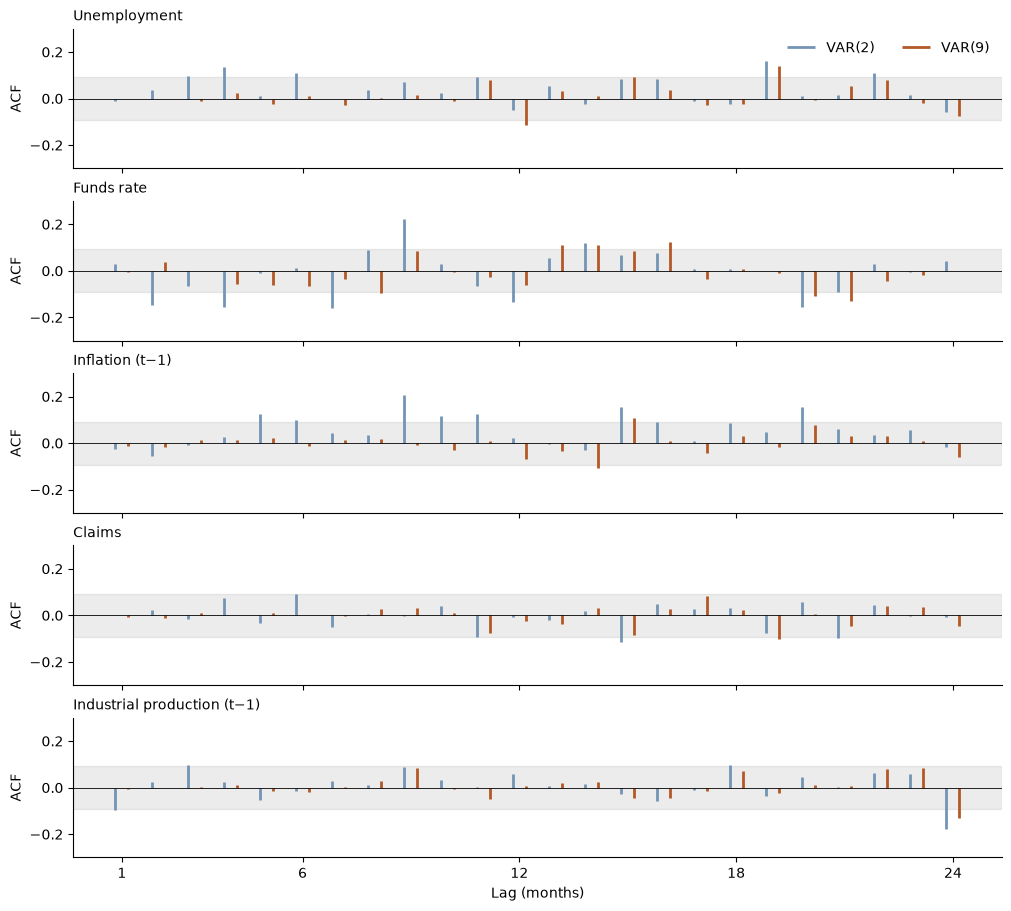

In [17]:
#| label: fig-var-resid
#| fig-cap: "Residual autocorrelation of each VAR equation, lags 1–24, for two and nine lags. Shaded bands are approximate 95% limits."
short = ["Unemployment", "Funds rate", "Inflation (t−1)", "Claims", "Industrial production (t−1)"]
fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True, layout="constrained")
for ax, name, title in zip(axes, VAR_COLUMNS, short):
    for K, color, offset in [(2, "#7394B5", -.18), (9, "#B35826", .18)]:
        values = acf(var_fits[K].resid[name], nlags=24, fft=False)[1:]
        ax.vlines(np.arange(1, 25) + offset, 0, values, color=color, linewidth=2, label=f"VAR({K})")
    ax.axhspan(-1.96 / np.sqrt(var_fits[2].nobs), 1.96 / np.sqrt(var_fits[2].nobs), color="gray", alpha=.15)
    ax.axhline(0, color="black", linewidth=.6)
    ax.set(ylabel="ACF", ylim=(-.3, .3))
    ax.set_title(title, loc="left", fontsize=10)
axes[0].legend(frameon=False, ncols=2, loc="upper right")
axes[-1].set(xlabel="Lag (months)", xticks=[1, 6, 12, 18, 24])
plt.show()

## Cointegration and the system candidates

In [18]:
#| label: tbl-cointegration
#| tbl-cap: "Cointegration tests on the training sample. Engle–Granger tests the single relationship with unemployment on the left; Johansen's sequential trace test counts relationships in the five-variable system (constant case, stop at the first non-rejection at 5%)."
eg_stat, eg_p, _ = coint(var_levels["UNRATE"], var_levels[VAR_COLUMNS[1:]], trend="c", maxlag=12, autolag="aic")
rows = [{"Test": "Engle–Granger", "Lag order K": "—", "Statistic": eg_stat, "5% critical value": np.nan,
         "Decision": f"p = {eg_p:.3f}: no rejection at 5%, rejection at 10%"}]
JOHANSEN_RANK = {}
for K in (2, 9):
    joh = coint_johansen(var_levels, det_order=0, k_ar_diff=K - 1)
    rank = next((r for r in range(5) if joh.lr1[r] <= joh.cvt[r, 1]), 5)
    assert rank == select_coint_rank(var_levels, det_order=0, k_ar_diff=K - 1, method="trace", signif=.05).rank
    JOHANSEN_RANK[K] = rank
    for r in range(rank + 1):
        rows.append({"Test": f"Johansen trace, H0: rank ≤ {r}", "Lag order K": K, "Statistic": joh.lr1[r],
                     "5% critical value": joh.cvt[r, 1],
                     "Decision": "Reject" if joh.lr1[r] > joh.cvt[r, 1] else f"Stop: rank {rank}"})
display(fmt(pd.DataFrame(rows).set_index("Test"), 2))

,Lag order K,Statistic,5% critical value,Decision
Test,,,,
Engle–Granger,—,-4.22,NaN,"p = 0.081: no rejection at 5%, rejection at 10%"
"Johansen trace, H0: rank ≤ 0",2,258.19,69.82,Reject
"Johansen trace, H0: rank ≤ 1",2,140.71,47.85,Reject
"Johansen trace, H0: rank ≤ 2",2,58.32,29.80,Reject
"Johansen trace, H0: rank ≤ 3",2,15.56,15.49,Reject
"Johansen trace, H0: rank ≤ 4",2,3.02,3.84,Stop: rank 4
"Johansen trace, H0: rank ≤ 0",9,103.38,69.82,Reject
"Johansen trace, H0: rank ≤ 1",9,50.54,47.85,Reject
"Johansen trace, H0: rank ≤ 2",9,29.19,29.80,Stop: rank 2


We obtain evidence of different strength from the two tests. Engle–Granger, which tests the residual of the levels regression in @tbl-ols, rejects no cointegration only at the 10% level. Johansen's trace test finds cointegration at both lag orders, selecting rank 4 with two lags and rank 2 with nine lags; both decisions sit close to their critical values. The trace test assumes serially uncorrelated innovations, and the nine-lag residuals come closer to that assumption (@fig-var-resid), so we give more weight to rank 2. We carry three candidates to validation: VAR(2), VAR(9), and a rank-2 VECM with nine levels lags (eight lagged differences) and an unrestricted constant. Comparing VAR(9) with the VECM isolates the effect of the rank restriction.

## Rolling validation

In [19]:
#| label: system-validation
system_data = regression_panel.loc["1961-02-01":"2011-12-01", VAR_COLUMNS].asfreq("MS")
assert system_data.notna().all().all()
SYSTEM_MODELS = ["VAR(2)", "VAR(9)", "VECM(9), rank 2"]


def system_forecast(history, name):
    """Fit on aligned history through the origin; return three-step unemployment forecasts."""
    if name.startswith("VAR"):
        K = int(name[4])
        fit = VAR(history).fit(K, trend="c")
        path = fit.forecast(history.to_numpy()[-K:], steps=3)
    else:
        fit = VECM(history, k_ar_diff=8, coint_rank=2, deterministic="co").fit()
        path = fit.predict(steps=3)
    assert np.isfinite(path).all()
    return path[:, 0]


rows = []
for origin in VALIDATION_ORIGINS:
    history = system_data.loc[:origin]
    for name in SYSTEM_MODELS:
        for h, value in enumerate(system_forecast(history, name), 1):
            rows.append({"Model": name, "Origin": origin, "Horizon": h,
                         "Target month": origin + pd.offsets.MonthBegin(h), "Forecast": float(value)})

perturbed = system_data.copy()
perturbed.loc[perturbed.index > VALIDATION_ORIGINS[0]] = perturbed.loc[perturbed.index > VALIDATION_ORIGINS[0]] * 1.7 + 123
first = pd.DataFrame(rows).query("Origin == @VALIDATION_ORIGINS[0]")
for name in SYSTEM_MODELS:
    np.testing.assert_allclose(system_forecast(perturbed.loc[:VALIDATION_ORIGINS[0]], name),
                               first.query("Model == @name")["Forecast"].to_numpy())

system_validation = attach_actuals(pd.concat([pd.DataFrame(rows), persistence_validation]),
                                   validation["UNRATE"], VALIDATION_ORIGINS)
vecm_training = VECM(var_levels, k_ar_diff=8, coint_rank=2, deterministic="co").fit()
vecm_portmanteau = {H: vecm_training.test_whiteness(nlags=H, adjusted=True).pvalue for H in (12, 24)}

In [20]:
#| label: tbl-system-validation
#| tbl-cap: "Rolling validation of the system candidates, January 1999–December 2011 targets (percentage points)."
display(fmt(accuracy_table(system_validation, ["Persistence"] + SYSTEM_MODELS)))

,Pairs,RMSE h=1,RMSE h=2,RMSE h=3,Pooled RMSE,Pooled MAE,RMSE / persistence,MAE / persistence
Model,,,,,,,,
Persistence,462,0.166,0.268,0.374,0.282,0.182,1.000,1.000
VAR(2),462,0.149,0.235,0.338,0.253,0.175,0.894,0.961
VAR(9),462,0.144,0.214,0.302,0.229,0.168,0.812,0.923
"VECM(9), rank 2",462,0.139,0.204,0.284,0.217,0.160,0.769,0.878


We find that the rank-2 VECM has the lowest validation RMSE at every horizon, with a pooled RMSE of 0.217 and a 23% improvement over persistence. It also beats VAR(9), so imposing two cointegrating relationships helped beyond the longer lag length. We freeze the **VECM with nine levels lags, rank 2, and an unrestricted constant**. Its training residuals still reject the portmanteau test (p < 0.001 at lags 12 and 24).

## What the linear system misses

We see three limits in the VECM. It estimates more than 200 coefficients from about 450 training months, its residuals keep some dependence even with nine lags, and its responses are linear: a predictor shock twice as large moves the forecast twice as far, whether the economy is expanding or entering a recession. Unemployment rises quickly at recession onsets and falls slowly during recoveries, and sharp increases in claims may matter more than proportionally. These features motivate a model that can learn thresholds and interactions.

# Tree-based ensembles {#sec-trees}

We test whether threshold and interaction effects, such as a sharp rise in claims, improve the forecasts. Tree ensembles learn such rules from the data without a specified functional form. We compare a **random forest**, which averages many decorrelated deep trees, with **gradient boosting**, which adds shallow trees as sequential corrections. Three design choices follow from how trees work:

1. **Changes as targets.** A regression tree predicts averages of its training targets, so a random forest, which averages trees, cannot predict outside the range of targets it has seen. Gradient boosting adds trees as corrections and can move somewhat beyond that range, but it still cannot follow an unbounded trend. For both ensembles we therefore predict $y_{t,h}=u_{t+h}-u_t$ and forecast $\hat u_{t+h\mid t}=u_t+\hat y_{t,h}$.
2. **Direct strategy.** We fit one model per horizon from the same origin features, so no predicted value or future predictor is fed back as an input.
3. **Origin-available features.** Every feature in @tbl-features uses only values dated at or before $t$ under the release rules of @tbl-variables.

In [21]:
#| label: tree-table
TREE_SEED = 546
tree_source = raw_panel.loc["1960-01-01":"2011-12-01", ["UNRATE", "FEDFUNDS", "CPIAUCSL", "CLAIMSx", "INDPRO"]].asfreq("MS")
assert tree_source.notna().all().all()


def build_tree_table(source):
    """Features shift and difference backward only; forward shifts build targets alone."""
    u, claims, ip = source["UNRATE"], np.log(source["CLAIMSx"]), np.log(source["INDPRO"])
    X = pd.DataFrame(index=source.index)
    X["u_level"] = u
    for lag in range(4):
        X[f"du_lag{lag}"] = u.diff().shift(lag)
    for w in (3, 12):
        X[f"u_change_{w}m"] = u.diff(w)
    X["log_claims"] = claims
    for w in (1, 3, 6):
        X[f"claims_log_change_{w}m"] = claims.diff(w)
    for w in (1, 3):
        X[f"ip_log_growth_{w}m_lag1"] = 100 * ip.diff(w).shift(1)
    X["cpi_inflation_lag1"] = (100 * np.log(source["CPIAUCSL"]).diff()).shift(1)
    X["funds_level"] = source["FEDFUNDS"]
    for w in (1, 3):
        X[f"funds_change_{w}m"] = source["FEDFUNDS"].diff(w)
    features = list(X.columns)
    for h in HORIZONS:
        X[f"target_h{h}"] = u.shift(-h) - u
        X[f"target_date_h{h}"] = X.index + pd.offsets.MonthBegin(h)
    return X.dropna(subset=features), features


tree_table, TREE_FEATURES = build_tree_table(tree_source)
assert len(TREE_FEATURES) == 17 and tree_table.index[0] == pd.Timestamp("1961-01-01")

In [22]:
#| label: tbl-features
#| tbl-cap: "The 17 tree features, all known at origin t. Growth rates are 100 × log changes."
feature_groups = pd.DataFrame([
    ("Unemployment", "Level $u_t$; monthly changes $\\Delta u_t,\\dots,\\Delta u_{t-3}$; 3- and 12-month changes", 7),
    ("Initial claims", "Log level; 1-, 3- and 6-month log changes", 4),
    ("Industrial production", "1- and 3-month growth ending at $t-1$", 2),
    ("CPI inflation", "Monthly inflation $\\pi_{t-1}$", 1),
    ("Federal funds rate", "Level; 1- and 3-month changes", 3),
], columns=["Variable", "Features", "Count"]).set_index("Variable")
assert feature_groups["Count"].sum() == len(TREE_FEATURES)
display(feature_groups)

,Features,Count
Variable,,
Unemployment,"Level $u_t$; monthly changes $\Delta u_t,\dots...",7
Initial claims,"Log level; 1-, 3- and 6-month log changes",4
Industrial production,1- and 3-month growth ending at $t-1$,2
CPI inflation,Monthly inflation $\pi_{t-1}$,1
Federal funds rate,Level; 1- and 3-month changes,3


## Training-only tuning

We choose hyperparameters by five-fold forward-chaining cross-validation within 1961–1998, because trees have no likelihood-based information criterion. This cross-validated RMSE plays the role that AIC and BIC played for the parametric models. We use `TimeSeriesSplit` with a gap of $h$ months, so no fitting target falls inside a held-out block. We restrict the grids to larger leaves, shallower boosting trees, and lower learning rates, which suit a sample of about 450 monthly observations:

- **Random forest** (500 trees): minimum leaf size {5, 10, 20} × feature fraction per split {0.33, 0.5}.
- **Gradient boosting** (row subsample 0.8, minimum leaf size 10): learning rate {0.03, 0.1} × depth {2, 3} × number of trees {100, 300, 600}.

We freeze the six selected settings (two models × three horizons) before validation and refit the trees at every later origin.

In [23]:
#| label: tbl-tree-tuning
#| tbl-cap: "Hyperparameters selected by training-only time-series cross-validation, with mean held-out RMSE across the five folds."
TREE_GRIDS = {"Random forest": {"min_samples_leaf": [5, 10, 20], "max_features": [0.33, 0.5]},
              "Gradient boosting": {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "n_estimators": [100, 300, 600]}}
TREE_MODELS = list(TREE_GRIDS)


def tree_estimator(name, settings):
    if name == "Random forest":
        return RandomForestRegressor(n_estimators=500, random_state=TREE_SEED, n_jobs=1, **settings)
    return GradientBoostingRegressor(subsample=.8, min_samples_leaf=10, random_state=TREE_SEED, **settings)


FROZEN_TREE_SETTINGS, tree_training_fits, rows = {}, {}, []
for h in HORIZONS:
    initial = tree_table.loc[tree_table[f"target_date_h{h}"] <= "1998-12-01"]
    split = TimeSeriesSplit(n_splits=5, gap=h)
    for fit_idx, hold_idx in split.split(initial):
        assert initial[f"target_date_h{h}"].iloc[fit_idx].max() < initial.index[hold_idx].min()
    for name in TREE_MODELS:
        search = GridSearchCV(tree_estimator(name, {}), TREE_GRIDS[name], cv=split,
                              scoring="neg_root_mean_squared_error", n_jobs=4, error_score="raise")
        with parallel_backend("threading", n_jobs=4):
            search.fit(initial[TREE_FEATURES], initial[f"target_h{h}"])
        FROZEN_TREE_SETTINGS[(name, h)] = dict(search.best_params_)
        tree_training_fits[(name, h)] = search.best_estimator_
        rows.append({"Model": name, "Horizon": h,
                     "Selected settings": ", ".join(f"{k} = {v}" for k, v in sorted(search.best_params_.items())),
                     "CV RMSE": -search.best_score_})
display(fmt(pd.DataFrame(rows).set_index(["Model", "Horizon"]).loc[TREE_MODELS]))

Selected settings  \
Model             Horizon                                                      
Random forest     1                max_features = 0.33, min_samples_leaf = 5   
                  2                 max_features = 0.5, min_samples_leaf = 5   
                  3                 max_features = 0.5, min_samples_leaf = 5   
Gradient boosting 1        learning_rate = 0.03, max_depth = 3, n_estimat...   
                  2        learning_rate = 0.03, max_depth = 3, n_estimat...   
                  3        learning_rate = 0.03, max_depth = 2, n_estimat...   

                           CV RMSE  
Model             Horizon           
Random forest     1          0.162  
                  2          0.230  
                  3          0.297  
Gradient boosting 1          0.163  
                  2          0.229  
                  3          0.295

We find that the forest prefers the smallest leaves at every horizon and that boosting prefers the slow learning rate. The two models reach nearly identical cross-validated RMSE in training, so we let validation decide between them.

## Rolling validation

In [24]:
#| label: tree-validation
def tree_forecast(table, origin, h, name):
    """Refit on rows whose target is already observed at the origin, then predict the change."""
    fitting = table.loc[table[f"target_date_h{h}"] <= origin]
    assert fitting[f"target_date_h{h}"].max() <= origin and fitting[f"target_h{h}"].notna().all()
    model = tree_estimator(name, FROZEN_TREE_SETTINGS[(name, h)])
    model.fit(fitting[TREE_FEATURES], fitting[f"target_h{h}"])
    return float(table.at[origin, "u_level"] + model.predict(table.loc[[origin], TREE_FEATURES])[0])


def tree_origin_rows(origin):
    return [{"Model": name, "Origin": origin, "Horizon": h, "Target month": origin + pd.offsets.MonthBegin(h),
             "Forecast": tree_forecast(tree_table, origin, h, name)} for h in HORIZONS for name in TREE_MODELS]


with ThreadPoolExecutor(max_workers=4) as pool:  # independent origins; seeds and settings unchanged
    rows = [row for chunk in pool.map(tree_origin_rows, VALIDATION_ORIGINS) for row in chunk]

perturbed = tree_source.copy()
perturbed.loc[perturbed.index > VALIDATION_ORIGINS[0]] = perturbed.loc[perturbed.index > VALIDATION_ORIGINS[0]] * 1.7 + 123
perturbed_table, _ = build_tree_table(perturbed)
first = pd.DataFrame(rows).query("Origin == @VALIDATION_ORIGINS[0]")
for row in first.itertuples():
    assert np.isclose(tree_forecast(perturbed_table, row.Origin, row.Horizon, row.Model), row.Forecast, atol=1e-12)

tree_validation = attach_actuals(pd.concat([pd.DataFrame(rows), persistence_validation]),
                                 validation["UNRATE"], VALIDATION_ORIGINS)

In [25]:
#| label: tbl-tree-validation
#| tbl-cap: "Rolling validation of the tree ensembles, January 1999–December 2011 targets (percentage points)."
tree_validation_table = accuracy_table(tree_validation, ["Persistence"] + TREE_MODELS)
display(fmt(tree_validation_table))
FROZEN_TREE_MODEL = tree_validation_table.loc[TREE_MODELS, "Pooled RMSE"].idxmin()

,Pairs,RMSE h=1,RMSE h=2,RMSE h=3,Pooled RMSE,Pooled MAE,RMSE / persistence,MAE / persistence
Model,,,,,,,,
Persistence,462,0.166,0.268,0.374,0.282,0.182,1.000,1.000
Random forest,462,0.134,0.198,0.274,0.210,0.151,0.744,0.829
Gradient boosting,462,0.137,0.205,0.288,0.219,0.154,0.775,0.846


We find that the random forest beats gradient boosting at all three horizons and improves on persistence by 26% in pooled RMSE and 17% in pooled MAE. We freeze the **random forest** with its three per-horizon settings (feature fraction 0.33 at one month and 0.5 at two and three months, minimum leaf size 5).

## What the forest relies on

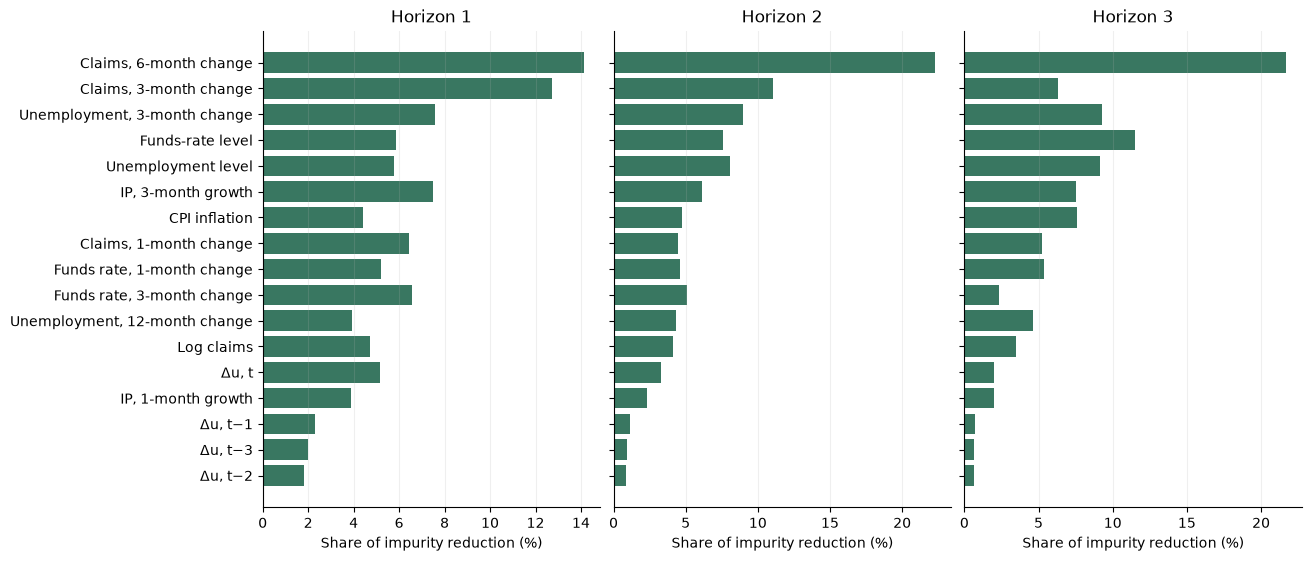

In [26]:
#| label: fig-importance
#| fig-cap: "Random-forest feature importance (share of squared-error reduction), refitted on the training period with the frozen settings."
names = {"u_level": "Unemployment level", "du_lag0": "Δu, t", "du_lag1": "Δu, t−1", "du_lag2": "Δu, t−2",
         "du_lag3": "Δu, t−3", "u_change_3m": "Unemployment, 3-month change", "u_change_12m": "Unemployment, 12-month change",
         "log_claims": "Log claims", "claims_log_change_1m": "Claims, 1-month change",
         "claims_log_change_3m": "Claims, 3-month change", "claims_log_change_6m": "Claims, 6-month change",
         "ip_log_growth_1m_lag1": "IP, 1-month growth", "ip_log_growth_3m_lag1": "IP, 3-month growth",
         "cpi_inflation_lag1": "CPI inflation", "funds_level": "Funds-rate level",
         "funds_change_1m": "Funds rate, 1-month change", "funds_change_3m": "Funds rate, 3-month change"}
importance = pd.DataFrame({h: 100 * tree_training_fits[("Random forest", h)].feature_importances_ for h in HORIZONS},
                          index=TREE_FEATURES)
order = importance.mean(axis=1).sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), sharey=True, layout="constrained")
for ax, h in zip(axes, HORIZONS):
    ax.barh([names[f] for f in order], importance.loc[order, h], color=MODEL_COLORS["Random forest"])
    ax.set(title=f"Horizon {h}", xlabel="Share of impurity reduction (%)")
    ax.grid(axis="x", alpha=.2)
plt.show()

We find that changes in claims over three and six months receive the largest shares at every horizon, followed by unemployment's level and three-month change and the funds-rate level. The forest therefore leans most on the labor-market inflow signal that motivated the multivariate models. We read these shares as a description of how the fitted trees split; correlated features share credit, and the shares carry no causal interpretation.

## What the forest cannot do

Each forest prediction is an average of changes observed in its training rows, so its predicted change can never exceed the largest change it has already seen. The forest therefore cannot anticipate a shock larger than any in its history, although it learns from such a shock once later origins include it.

# Final test, 2012–2024 {#sec-test}

## Frozen specifications

| Model | Frozen specification | Re-estimated at each origin |
|---|---|---|
| Persistence | $\hat u_{t+h\mid t}=u_t$ | Nothing |
| ARIMA(4,1,1) | No drift, no seasonal terms | AR and MA coefficients |
| VECM(9), rank 2 | Five aligned series, eight lagged differences, unrestricted constant | $\alpha$, $\beta$, $\Gamma_j$, constant |
| Random forest | 17 features; 500 trees; leaf size 5; feature fraction 0.33 ($h=1$) or 0.5 ($h=2,3$) | Trees for each horizon |

: Specifications frozen before the test run. {#tbl-frozen}

We ran the test once with these specifications on 154 origins (December 2011–September 2024). For ARIMA and the VECM we also stored 90% prediction intervals.

In [27]:
#| label: final-test
FINAL_MODELS = ["Persistence", "ARIMA(4,1,1)", "VECM(9), rank 2", "Random forest"]
final_source = raw_panel.loc["1960-01-01":"2024-12-01", ["UNRATE", "FEDFUNDS", "CPIAUCSL", "CLAIMSx", "INDPRO"]].asfreq("MS")
assert final_source.notna().all().all()
results_dir = project / "results" / "final_test"
results_dir.mkdir(parents=True, exist_ok=True)
FINAL_TEST_SPEC = {"ARIMA": {"order": [4, 1, 1], "trend": "n"},
                   "VECM": {"k_ar_diff": 8, "coint_rank": 2, "deterministic": "co"},
                   "Random forest": {h: {"n_estimators": 500, "random_state": TREE_SEED,
                                         **FROZEN_TREE_SETTINGS[("Random forest", h)]} for h in HORIZONS}}
(results_dir / "frozen_specifications.json").write_text(json.dumps(FINAL_TEST_SPEC, indent=2))


def final_origin_rows(source_history):
    """Receives observations through one origin only and returns all four models' forecasts."""
    origin = source_history.index[-1]
    u = source_history.loc[ANALYSIS_START:, "UNRATE"]
    arima, _ = arima_forecast(u, (4, 1, 1))
    arima_fc = arima.get_forecast(steps=3)
    arima_ci = arima_fc.conf_int(alpha=.10).to_numpy()
    aligned = source_history[["UNRATE", "FEDFUNDS", "CLAIMSx"]].copy()
    aligned["CPI_inflation_mlog_lag1"] = (100 * np.log(source_history["CPIAUCSL"]).diff()).shift(1)
    aligned["INDPRO_lag1"] = source_history["INDPRO"].shift(1)
    aligned = aligned.loc["1961-02-01":, VAR_COLUMNS]
    vecm_point, vecm_lower, vecm_upper = VECM(aligned, **FINAL_TEST_SPEC["VECM"]).fit().predict(steps=3, alpha=.10)
    table, features = build_tree_table(source_history)
    forest = [tree_forecast(table, origin, h, "Random forest") for h in HORIZONS]
    paths = {"Persistence": (np.repeat(u.iloc[-1], 3), None, None),
             "ARIMA(4,1,1)": (arima_fc.predicted_mean.to_numpy(), arima_ci[:, 0], arima_ci[:, 1]),
             "VECM(9), rank 2": (vecm_point[:, 0], vecm_lower[:, 0], vecm_upper[:, 0]),
             "Random forest": (np.array(forest), None, None)}
    return [{"Model": m, "Origin": origin, "Horizon": h, "Target month": origin + pd.offsets.MonthBegin(h),
             "Forecast": float(point[h - 1]),
             "Lower 90%": np.nan if lo is None else float(lo[h - 1]),
             "Upper 90%": np.nan if hi is None else float(hi[h - 1])}
            for m, (point, lo, hi) in paths.items() for h in HORIZONS]


with ThreadPoolExecutor(max_workers=4) as pool:
    rows = [r for chunk in pool.map(lambda o: final_origin_rows(final_source.loc[:o]), TEST_ORIGINS) for r in chunk]
final_forecasts = pd.DataFrame(rows)
final_forecasts.to_csv(results_dir / "forecasts_before_scoring.csv", index=False)  # saved before outcomes exist

perturbed = final_source.copy()
perturbed.loc[perturbed.index > TEST_ORIGINS[0]] = perturbed.loc[perturbed.index > TEST_ORIGINS[0]] * 1.7 + 123
check = pd.DataFrame(final_origin_rows(perturbed.loc[:TEST_ORIGINS[0]]))
np.testing.assert_allclose(check["Forecast"], final_forecasts.query("Origin == @TEST_ORIGINS[0]")["Forecast"], atol=1e-10)

final_scored = attach_actuals(final_forecasts, final_source["UNRATE"], TEST_ORIGINS)
final_scored.to_csv(results_dir / "scored_forecasts.csv", index=False)
final_table = accuracy_table(final_scored, FINAL_MODELS)
final_table.to_csv(results_dir / "scores.csv")

## Accuracy

In [28]:
#| label: tbl-test
#| tbl-cap: "Final test accuracy, January 2012–December 2024 targets (percentage points)."
display(fmt(final_table))

,Pairs,RMSE h=1,RMSE h=2,RMSE h=3,Pooled RMSE,Pooled MAE,RMSE / persistence,MAE / persistence
Model,,,,,,,,
Persistence,462,0.900,1.280,1.498,1.251,0.371,1.000,1.000
"ARIMA(4,1,1)",462,1.157,1.845,2.259,1.811,0.522,1.448,1.408
"VECM(9), rank 2",462,2.857,5.007,4.293,4.150,0.946,3.318,2.554
Random forest,462,0.920,1.293,1.525,1.271,0.371,1.016,1.002


We find that persistence has the lowest pooled RMSE and MAE in the test. The random forest nearly ties it, while ARIMA and the VECM are clearly worse. This ranking reverses the validation results, where every family beat persistence by roughly 20%. We test in @tbl-dm whether these differences exceed the noise in overlapping forecast errors.

In [29]:
#| label: tbl-dm
#| tbl-cap: "Diebold–Mariano tests of squared-error loss against persistence. A positive mean difference means the model's squared errors are larger; the variance uses Newey–West weights with h − 1 lags because h-step errors overlap."
def diebold_mariano(model_err, base_err, h):
    d = model_err ** 2 - base_err ** 2
    d_c, T = d - d.mean(), len(d)
    variance = d_c @ d_c / T + 2 * sum((1 - k / h) * (d_c[k:] @ d_c[:-k]) / T for k in range(1, h))
    stat = d.mean() / np.sqrt(variance / T)
    return d.mean(), stat, 2 * norm.sf(abs(stat))


rows = []
for name in FINAL_MODELS[1:]:
    for h in HORIZONS:
        err = final_scored.query("Model == @name and Horizon == @h").sort_values("Origin")["Error"].to_numpy()
        base = final_scored.query("Model == 'Persistence' and Horizon == @h").sort_values("Origin")["Error"].to_numpy()
        mean_d, stat, p = diebold_mariano(err, base, h)
        rows.append({"Model": name, "Horizon": h, "Mean loss difference": mean_d, "DM statistic": stat, "p-value": p})
display(fmt(pd.DataFrame(rows).set_index(["Model", "Horizon"])))

Mean loss difference  DM statistic  p-value
Model           Horizon                                             
ARIMA(4,1,1)    1                       0.527         1.657    0.098
                2                       1.765         1.492    0.136
                3                       2.857         1.277    0.202
VECM(9), rank 2 1                       7.350         1.882    0.060
                2                      23.427         1.529    0.126
                3                      16.187         1.077    0.281
Random forest   1                       0.036         0.537    0.591
                2                       0.033         0.328    0.743
                3                       0.080         0.708    0.479

We cannot reject equal accuracy with persistence at the 5% level for any model or horizon. ARIMA and the VECM come closest at one month (p = 0.10 and p = 0.06), and the random forest's p-values are 0.48 or higher. We read these results cautiously. A failure to reject leaves open whether the forest and persistence are equally accurate, and the test has little power here because a few months with very large errors drive both the mean loss difference and its variance. Our variance uses $h-1$ Newey–West lags, which accounts for the overlap of $h$-step targets; loss differences that cluster over a longer episode, as in 2020, would call for a longer bandwidth, which we have not examined. We locate those months next.

## Where the models fail

In [30]:
#| label: tbl-periods
#| tbl-cap: "Test RMSE by target-month period. Every model is scored on the same pairs within each period."
periods = pd.cut(final_scored["Target month"], pd.to_datetime(["2012-01-01", "2016-01-01", "2020-01-01", "2025-01-01"]),
                 right=False, labels=["2012–2015", "2016–2019", "2020–2024"])
by_period = (final_scored.assign(Period=periods, SE=final_scored["Error"] ** 2)
             .groupby(["Period", "Model"], observed=True)["SE"].agg(["size", "mean"]))
period_table = np.sqrt(by_period["mean"]).unstack("Model")[FINAL_MODELS]
period_table.insert(0, "Pairs per model", by_period["size"].unstack("Model")["Persistence"])
covid = final_scored.assign(SE=final_scored["Error"] ** 2)
covid_share = (covid[covid["Target month"].between("2020-03-01", "2020-12-01")].groupby("Model")["SE"].sum()
               / covid.groupby("Model")["SE"].sum())
period_table.to_csv(results_dir / "rmse_by_period.csv")
display(fmt(period_table))

Model,Pairs per model,Persistence,"ARIMA(4,1,1)","VECM(9), rank 2",Random forest
Period,,,,,
2012–2015,141,0.232,0.209,0.197,0.171
2016–2019,144,0.146,0.148,0.154,0.130
2020–2024,177,2.006,2.917,6.700,2.044


We find that the test ranking hinges on a single episode. In 2012–2015 every model beats persistence, and the random forest has the lowest RMSE (0.171 against 0.232). In 2016–2019 the forest again leads (0.130 against 0.146), while ARIMA and the VECM fall slightly behind persistence. In 2020–2024 persistence is best (2.006), the forest is close (2.044), and ARIMA (2.917) and the VECM (6.700) fall far behind. Target months from March to December 2020 account for 97–99% of every model's squared test error. We show in @fig-shock how each model behaved around that shock.

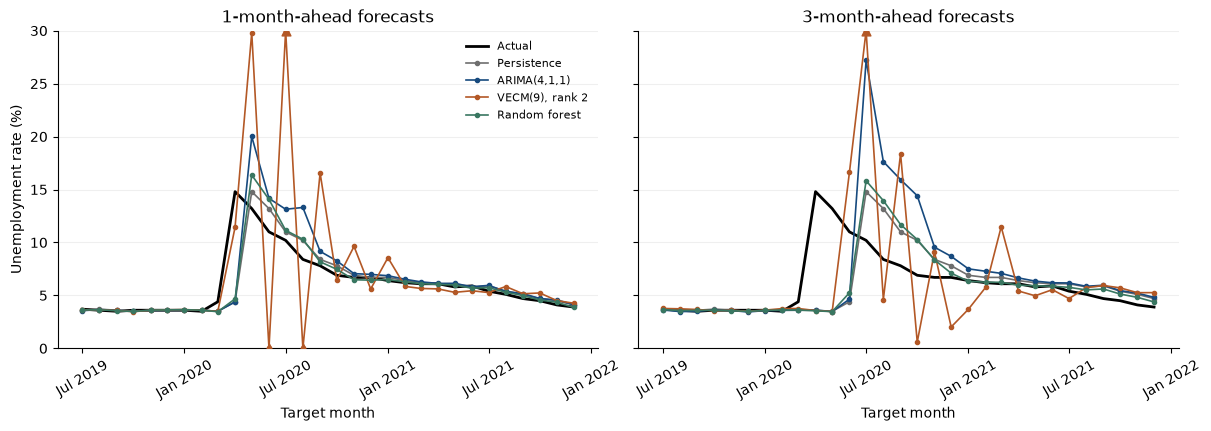

In [31]:
#| label: fig-shock
#| fig-cap: "One- and three-month-ahead test forecasts around the 2020 shock, plotted at their target months. The vertical axis is capped at 30%; VECM forecasts beyond the cap or below zero are marked at the plot edge."
import matplotlib.dates as mdates
window = final_scored[final_scored["Target month"].between("2019-07-01", "2021-12-01")]
actual = final_source.loc["2019-07-01":"2021-12-01", "UNRATE"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, layout="constrained")
for ax, h in zip(axes, (1, 3)):
    ax.plot(actual.index, actual, color="black", linewidth=2, label="Actual")
    for name in FINAL_MODELS:
        s = window.query("Model == @name and Horizon == @h").set_index("Target month")["Forecast"]
        clipped = s.clip(0, 30)
        ax.plot(clipped.index, clipped, color=MODEL_COLORS[name], linewidth=1.2, marker="o", markersize=3, label=name)
        off = s[(s > 30) | (s < 0)]
        ax.scatter(off.index, off.clip(0, 30), marker="^", s=40, color=MODEL_COLORS[name], zorder=3)
    ax.set(title=f"{h}-month-ahead forecasts", ylim=(0, 30), xlabel="Target month")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Unemployment rate (%)")
axes[0].legend(frameon=False, fontsize=8)
plt.show()

Initial claims averaged 2.34 million in March 2020 and 4.66 million in April, 3.5 and 7 times the training-period maximum of 0.66 million. We trace each model's failure to how it handles inputs and changes of that size:

- **VECM.** At the March origin the VECM was the only model to forecast a large April increase (11.4% against an actual 14.8%), because its linear claims coefficients scaled up the unprecedented surge. The same linear scaling then made its forecasts explode: from the April origin it projected 58.5% for July, and over the following origins it swung between negative and implausibly high values.
- **ARIMA.** ARIMA missed the April jump and then carried it forward as momentum: from the April origin it forecast 20.0%, 23.9%, and 27.2% for May through July, while unemployment fell to 13.2%, 11.0%, and 10.2%.
- **Random forest.** The forest moved only modestly at the March origin (4.7%), because no training change came close to a 10-point jump. After April it stayed near the latest observed rate and tracked the decline, so its errors stayed close to those of persistence.
- **Persistence.** Persistence also missed April by 10.4 points and then overshot during the recovery, because it carried each elevated rate forward (14.8% for May against an actual 13.2%). It avoided the additional extrapolation that ARIMA and the VECM layered on top, which is why it has the lowest 2020–2024 RMSE in @tbl-periods.

We conclude that the models with the most structure failed most when their inputs left the range they were estimated on. The forest's bounded response, which we flagged as a limitation in @sec-trees, protected it during the shock.

## Prediction intervals

In [32]:
#| label: tbl-coverage
#| tbl-cap: "Empirical coverage and mean width of the 90% prediction intervals, by period. The random forest and persistence do not produce intervals."
cov = final_scored.dropna(subset=["Lower 90%"]).assign(Period=periods)
cov["Covered"] = cov["Actual"].between(cov["Lower 90%"], cov["Upper 90%"])
cov["Width"] = cov["Upper 90%"] - cov["Lower 90%"]
cov["Period"] = np.where(cov["Target month"] < "2020-01-01", "2012–2019", "2020–2024")
coverage = cov.groupby(["Model", "Period"]).agg(Pairs=("Covered", "size"), Coverage=("Covered", "mean"),
                                                 **{"Mean width": ("Width", "mean")})
display(fmt(coverage))

Pairs  Coverage  Mean width
Model           Period                                
ARIMA(4,1,1)    2012–2019    285     0.965       0.764
                2020–2024    177     0.842       1.892
VECM(9), rank 2 2012–2019    285     0.947       0.643
                2020–2024    177     0.712       1.418

We find that the 90% intervals of ARIMA and the VECM are slightly conservative before 2020, covering 96.5% and 94.7% of outcomes. From 2020 onward coverage falls to 84.2% and 71.2%, because intervals estimated on calm history assume Gaussian shocks far smaller than the 2020 jump. We have no intervals for the random forest or persistence, which limits our uncertainty assessment for the model we would recommend.

## Model-risk register

| Risk | What could go wrong | What we did | Remaining limitation | Monitoring or retraining trigger |
|---|---|---|---|---|
| Target leakage | A model trains on outcomes dated after its origin. | Expanding windows; assertions on every training cutoff; forecasts saved before outcomes are joined; future-data perturbation check in every stage. | The checks cover our code paths only. | Rerun the checks after any code change. |
| Future-information assumptions | A forecast uses values not yet published. | CPI and industrial production enter with a one-month lag; the tree features look backward only. | Claims' final week value of a given month may be pending on an early release date; we did not reconstruct release calendars. | Verify the release calendar each year; lag claims one month if the jobs report precedes the final claims week. |
| Data revisions | Revised data overstate real-time accuracy. | Fixed January 2026 snapshot with checksum. | Results are retrospective; real-time vintages are untested. | Re-estimate after annual benchmark revisions. |
| Inputs outside the training range | Linear models extrapolate unprecedented inputs. | Period breakdown and shock diagnostics (@fig-shock). | March–April 2020 claims were 3.5–7 times the training maximum; the VECM and ARIMA overshot, and the forest cannot anticipate unseen changes. | Flag any input outside its historical range or any forecast change above 1 point per month; report persistence for that origin and review the model. |
| Specification uncertainty | Selected lags, rank, or candidates do not generalize. | Tested the rank at two lag orders; in validation, compared two lag orders and the rank-2 restriction against the unrestricted VAR(9); disclosed the post-hoc ARIMA(4,1,1) candidate; tuned trees on training only. | The Johansen rank depends on the lag order, and the rank-4 alternative was never forecast-evaluated; selection on validation is mildly optimistic. | Re-run the selection if the chosen model's rolling 12-month RMSE exceeds persistence for six consecutive months. |
| Uncertainty quantification | Intervals are too narrow or missing. | Reported 90% coverage for ARIMA and the VECM and Diebold–Mariano tests. | Residual dependence remains; the forest has no intervals. | Recalibrate if rolling 24-month coverage falls below 80%. |

: Model-risk register. {#tbl-risk}

# Conclusion

We set out to beat persistence when forecasting unemployment one to three months ahead. In validation (1999–2011), every family improved on persistence in pooled RMSE: ARIMA by 19%, the VECM by 23%, and the random forest by 26%. In the test (2012–2024), persistence achieved the lowest pooled RMSE, so under our predeclared criterion it is the best evaluated procedure. We could not reject equal accuracy for any model, and the 2020 shock dominated every error measure. The random forest came closest to persistence overall. In our post-test breakdown it was the most accurate model in 2012–2015 and 2016–2019, and during the shock it stayed close to persistence while ARIMA and especially the VECM overshot.

We attribute the test-period failures to two related features of the data. First, the 2020 shock pushed inputs far outside their estimated range: initial claims reached 3.5 to 7 times their training maximum, and the linear models extrapolated their estimated relationships to inputs they had never seen. The shock may also have changed those relationships, since many 2020 layoffs were temporary and unemployment fell faster than past claims surges would imply; our analysis is consistent with this but does not test it. Second, our expanding window weights data from the 1960s onward equally at every origin, so the estimated relationships partly reflect earlier policy and labor-market regimes. The reversal from validation to test, and the slight underperformance of ARIMA and the VECM relative to persistence in 2016–2019, are consistent with such structural change. Rolling estimation windows or formal break tests would address this, and we leave them to future work.
